# 04. Bertalmio: propagación a lo largo de las isófotas

Este cuaderno prueba la implementación de `src/bertalmio.py`, que sigue el artículo de Bertalmio, Sapiro, Caselles y Ballester, «Image inpainting» (SIGGRAPH 2000), que citamos como [1] con la página impresa (pp. 417 a 424).

**Resumen del estado:** el método reproduce el ejemplo sintético de la Fig. 4 del artículo (contornos que atraviesan un hueco en forma de anillo), con la mitad de error que la difusión simple. Funciona bien cuando hay **bordes y contornos** que cruzan el hueco. No mejora a la media con **líneas finas** ni con **texturas**, y es mucho más lento. Para que funcione hace falta un buen **valor de partida** del hueco (sección 5).

**Para ver el algoritmo funcionando**, la sección 2 lo enseña iteración a iteración, con las isófotas, el gradiente y lo que cambia en cada paso y en cada ciclo.

## La idea

Se prolongan hacia dentro del hueco las **isófotas** (líneas de igual valor de gris) que llegan a su borde, manteniendo su ángulo [1, sec. 3.1, p. 418]. Para ello, dentro del hueco se repite

$$I^{n+1}=I^{n}+\Delta t\,I_t^{n}$$

[1, ecs. (1) y (4), pp. 418-419], donde la actualización $I_t=\delta L\cdot N$ [1, ec. (2), p. 419] propaga una medida de suavidad $L$ en la dirección $N$ de las isófotas. Cada cierto número de pasos se intercala difusión anisotrópica [1, ec. (3), p. 419].

## De la ecuación al código

| Qué | Dónde en [1] | Función |
|---|---|---|
| Medida de suavidad $L=I_{xx}+I_{yy}$ | sec. 3.2, p. 419; ec. (7), p. 420 | `laplaciano` |
| Cambio de $L$ entre vecinos, $\delta L$ | ec. (6), p. 420 | dentro de `paso_inpainting` |
| Dirección de las isófotas $N/\lvert N\rvert=(-I_y,I_x)/\lvert\nabla I\rvert$ | sec. 3.2, p. 419; ec. (8), p. 420 | `direccion_isofotas` |
| Proyección $\beta=\delta L\cdot N/\lvert N\rvert$ | ec. (9), p. 420 | dentro de `paso_inpainting` |
| Gradiente con limitadores de pendiente | ec. (10), p. 420 | dentro de `paso_inpainting` |
| Actualización $I_t=\beta\lvert\nabla I\rvert$, solo en el hueco | ecs. (5) y (4), pp. 419-420 | `paso_inpainting` |
| Difusión anisotrópica $\partial I/\partial t=\kappa\lvert\nabla I\rvert$ | ec. (3), p. 419 | `paso_difusion` |
| 15 pasos de inpainting y 2 de difusión, $\Delta t=0{,}1$ | sec. 3.3, p. 420 | `bertalmio` |
| Preproceso con difusión anisotrópica | sec. 3.3, p. 419 | `bertalmio` (`pasos_previos`) |
| Modelo de color para evitar colores falsos | sec. 3.3, p. 420; Fig. 3 | `rgb_a_modelo`, `modelo_a_rgb` |

Hemos comparado las fórmulas con una implementación pública del mismo método, la de Parisotto y Schönlieb (repositorio `MATLAB-Python-inpainting-codes`, licencia BSD-3), y coinciden: la misma rotación de $N$, el mismo limitador de pendiente y valores entre 0 y 1. No usamos su código.

## Decisiones y simplificaciones nuestras

- **Valor de partida del hueco:** por defecto, el resultado de la difusión simple (sección 5). El artículo no lo fija.
- La difusión anisotrópica se aplica solo dentro del hueco (en el artículo, $g_\epsilon$ vale 1 dentro y baja a 0 en una banda de ancho $\epsilon$ fuera).
- No usamos multirresolución [1, nota 10, p. 420].
- El modelo de color es nuestra lectura de la Fig. 3.
- El número de pasos del preproceso (`pasos_previos`) lo elegimos nosotros: el artículo no lo indica.
- Trabajamos con valores entre 0 y 1 (sección 3).

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

import mascaras as m
import metricas as k
import difusion as d
import bertalmio as b

## 1. Comprobaciones de las piezas

### El laplaciano

Un punto de valor 100 rodeado de ceros: en el punto, $0+0+0+0-4\cdot100=-400$, y en cada vecino, $100$.

In [2]:
punto = np.zeros((5, 5))
punto[2, 2] = 100
L = b.laplaciano(punto)
print("Laplaciano en el punto:", L[2, 2], "(a mano: -400)")
print("Laplaciano en un vecino:", L[1, 2], "(a mano: 100)")
assert L[2, 2] == -400 and L[1, 2] == 100

Laplaciano en el punto: -400.0 (a mano: -400)
Laplaciano en un vecino: 100.0 (a mano: 100)


### La dirección de las isófotas

En un borde **vertical** las líneas de igual valor son verticales, y en uno **horizontal**, horizontales. Recordamos que «x» es el primer índice (filas) e «y» el segundo (columnas): el vector $(N_x, N_y)=(-1,0)$ apunta a lo largo de las filas, es decir, en vertical.

In [3]:
vertical = np.zeros((9, 9))
vertical[:, 5:] = 1
Nx, Ny = b.direccion_isofotas(vertical)
print("Borde vertical, en el borde: (N_x, N_y) =", (Nx[4, 5], Ny[4, 5]), "-> a lo largo de las filas, es decir, en vertical")
assert abs(Nx[4, 5]) == 1 and Ny[4, 5] == 0

horizontal = np.zeros((9, 9))
horizontal[5:, :] = 1
Nx, Ny = b.direccion_isofotas(horizontal)
print("Borde horizontal, en el borde: (N_x, N_y) =", (Nx[5, 4], Ny[5, 4]), "-> a lo largo de las columnas, es decir, en horizontal")
assert Nx[5, 4] == 0 and abs(Ny[5, 4]) == 1

Borde vertical, en el borde: (N_x, N_y) = (np.float64(-1.0), np.float64(0.0)) -> a lo largo de las filas, es decir, en vertical
Borde horizontal, en el borde: (N_x, N_y) = (np.float64(-0.0), np.float64(1.0)) -> a lo largo de las columnas, es decir, en horizontal


### El estado estacionario

En una **rampa** lineal el laplaciano vale 0, así que no hay nada que propagar y la imagen no debe cambiar ($I_t=0$ [1, pp. 419-420]).

In [4]:
rampa = np.tile(np.arange(30) * 0.01, (30, 1))
hueco_rampa = np.zeros((30, 30), dtype=bool)
hueco_rampa[12:18, 12:18] = True

cambio = np.abs(b.paso_inpainting(rampa, hueco_rampa, 0.1) - rampa).max()
print("Cambio máximo en un paso de inpainting sobre una rampa:", cambio)
assert cambio < 1e-12

Cambio máximo en un paso de inpainting sobre una rampa: 0.0


### La difusión anisotrópica

La difusión de la ecuación (3) mueve las líneas según su **curvatura**: un borde recto tiene curvatura 0 y no cambia, mientras que una forma redonda se va encogiendo.

In [5]:
todo = np.ones((60, 60), dtype=bool)

recto = np.zeros((60, 60))
recto[:, 30:] = 1
print("Borde recto, cambio máximo en un paso:", np.abs(b.paso_difusion(recto, todo, 0.1) - recto).max())
assert np.abs(b.paso_difusion(recto, todo, 0.1) - recto).max() == 0

filas, columnas = np.mgrid[0:60, 0:60]
disco = (((filas - 30) ** 2 + (columnas - 30) ** 2) <= 15 ** 2).astype(float)
encogido = disco.copy()
for _ in range(200):
    encogido = b.paso_difusion(encogido, todo, 0.1)
print("Disco: píxeles claros antes", int((disco > 0.5).sum()), "y después de 200 pasos", int((encogido > 0.5).sum()))
assert (encogido > 0.5).sum() < (disco > 0.5).sum()

Borde recto, cambio máximo en un paso: 0.0
Disco: píxeles claros antes 709 y después de 200 pasos 593


## 2. Qué hace cada iteración, paso a paso

Hasta aquí hemos comprobado las piezas por separado. Ahora vemos el algoritmo **funcionando**, sobre un ejemplo pequeño: un borde inclinado (gris oscuro a la izquierda y claro a la derecha) con un hueco cuadrado de 16×16 encima. En vez de llamar a `bertalmio` como una caja negra, repetimos aquí su bucle **guardando la imagen en cada momento**, para poder dibujarla.

Dibujamos tres cosas:

- las **isófotas**, en azul: líneas que unen los píxeles del mismo valor de gris (se pintan con `plt.contour`). Si el algoritmo funciona, las que llegan al hueco por fuera tienen que ir continuándose por dentro;
- el **gradiente** $\nabla I$, que apunta hacia donde más cambia la imagen, y la dirección $N$ de las isófotas, que es ese gradiente girado 90 grados;
- lo que **cambia** en cada paso, en rojo (sube) y azul (baja). En esos mapas el hueco va marcado con una línea amarilla.

Estas funciones son solo para el cuaderno (no están en `src`) y **no cambian nada del algoritmo**: lo comprobamos al final de la celda comparando con `b.bertalmio`.

In [6]:
# ---- Funciones de ayuda, solo para este cuaderno ----

def preparar(danada, hueco, margen=3):
    # Repite lo que hace b.bertalmio antes de empezar a iterar: valor de partida con la
    # difusión simple, recorte de la zona de trabajo, borde extra y preproceso.
    base, _ = d.difusion_simple(danada, hueco)
    filas, columnas = np.nonzero(hueco)
    zona = (slice(max(filas.min() - margen, 0), min(filas.max() + margen + 1, hueco.shape[0])),
            slice(max(columnas.min() - margen, 0), min(columnas.max() + margen + 1, hueco.shape[1])))
    A = np.pad(base[zona].astype(np.float64) / 255, margen, mode="edge")
    h = np.pad(hueco[zona], margen, constant_values=False)
    for _ in range(5):
        A = b.paso_difusion(A, np.ones_like(h), 0.1)
    return A, h, zona


def historial(A, h, ciclos, pasos_inpainting=15, pasos_difusion=2, dt=0.1):
    # Repite el bucle de b.bertalmio y guarda la imagen al acabar cada ciclo
    # (tras_ciclo) y justo antes de los pasos de difusión (tras_inpainting).
    tras_ciclo = [A.copy()]
    tras_inpainting = [A.copy()]
    for _ in range(ciclos):
        for _ in range(pasos_inpainting):
            A = b.paso_inpainting(A, h, dt)
        tras_inpainting.append(A.copy())
        for _ in range(pasos_difusion):
            A = b.paso_difusion(A, h, dt)
        tras_ciclo.append(A.copy())
    return tras_ciclo, tras_inpainting


def error_por_ciclo(estados, h, original_zona, margen=3):
    # MSE del hueco (en niveles de gris, de 0 a 255) de cada imagen guardada.
    dentro = h[margen:-margen, margen:-margen]
    return [np.mean(((A[margen:-margen, margen:-margen] - original_zona)[dentro] * 255) ** 2) for A in estados]


def ventana(h, margen=5):
    # Rectángulo que rodea al hueco, para dibujar solo esa parte.
    filas, columnas = np.nonzero(h)
    return (slice(filas.min() - margen, filas.max() + margen + 1),
            slice(columnas.min() - margen, columnas.max() + margen + 1))


def marcar_hueco(ax, hueco_ventana):
    ax.contour(hueco_ventana.astype(float), levels=[0.5], colors="yellow", linewidths=1.2)

In [7]:
# ---- El ejemplo: borde inclinado con un hueco de 16x16 ----
N = 64
fila_s, columna_s = np.mgrid[0:N, 0:N]
borde_i = np.where(2 * columna_s - fila_s >= 30, 220, 40).astype(np.uint8)
hueco_i = m.mascara_cuadrada((N, N), 16, (30, 28))
danada_i = m.aplicar_mascara(borde_i, hueco_i)

A0, h, zona = preparar(danada_i, hueco_i)
original_zona = borde_i[zona] / 255
w = ventana(h)
hv = h[w]
niveles = np.linspace(0.1, 0.9, 9)      # las mismas isófotas en todas las figuras

# Comprobación: nuestro bucle da lo mismo que b.bertalmio con 40 ciclos.
estados_40, _ = historial(A0, h, 40)
con_nuestro_bucle = np.rint(estados_40[-1][3:-3, 3:-3] * 255)
con_bertalmio, _ = b.bertalmio(danada_i, hueco_i, ciclos=40, tolerancia=0)
diferencia = np.abs(con_nuestro_bucle[h[3:-3, 3:-3]] - con_bertalmio[zona][h[3:-3, 3:-3]]).max()
print("Diferencia máxima con b.bertalmio:", diferencia)
assert diferencia == 0

Diferencia máxima con b.bertalmio: 0.0


### 2.1 Un solo paso, por dentro

Es el **primer paso de inpainting**, justo después del valor de partida (la difusión simple). Cada panel es una de las cantidades de las ecuaciones (6) a (10) de [1, p. 420]:

1. $I$ con sus **isófotas**. Con el valor de partida, las isófotas de fuera entran al hueco, se abren y se curvan para unirse unas con otras. Todavía no continúan el borde recto.
2. $L=I_{xx}+I_{yy}$ (el laplaciano, ec. (7)): dónde la imagen no es «suave».
3. En azul, la dirección del **gradiente**; en naranja, la dirección $N$ de las isófotas, que es el gradiente girado 90 grados (ec. (8)). Se ven siempre perpendiculares.
4. $\beta=\delta L\cdot N/\lvert N\rvert$ (ec. (9)): cuánto cambia $L$ al avanzar a lo largo de la isófota.
5. $\Delta t\,I_t=\Delta t\,\beta\,\lvert\nabla I\rvert$ (ecs. (5) y (10)): lo que se suma a cada píxel en este paso.

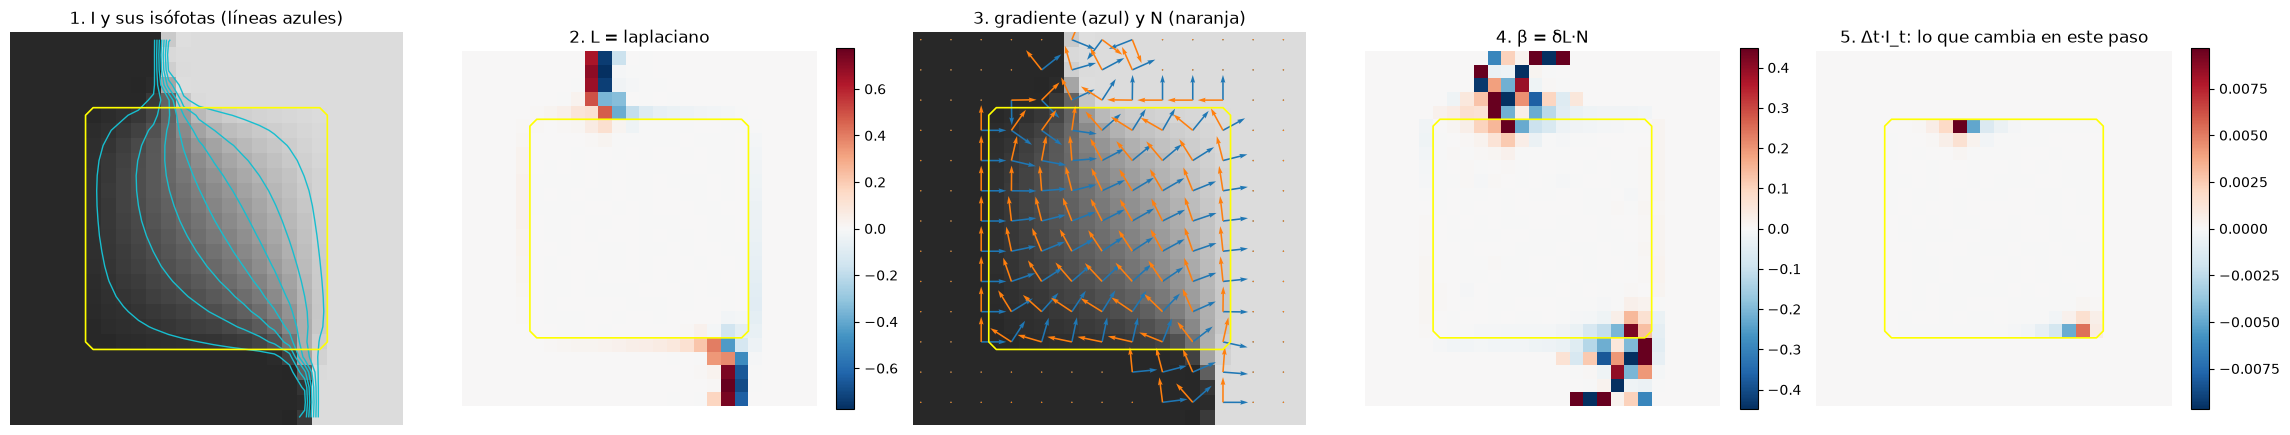

Píxeles del hueco: 256. Cambio máximo en este paso: 2.47 niveles de gris.
Píxeles que cambian más de un 5 % de ese máximo: 15.


In [8]:
A = A0
L = b.laplaciano(A)
cambio_L_x = b._x(L, 1) - b._x(L, -1)
cambio_L_y = b._y(L, 1) - b._y(L, -1)
N_x, N_y = b.direccion_isofotas(A)
beta = cambio_L_x * N_x + cambio_L_y * N_y
nueva = b.paso_inpainting(A, h, 0.1)
cambio_paso = nueva - A

# Gradiente (con diferencias centrales, como en direccion_isofotas) y su módulo.
G_x = (b._x(A, 1) - b._x(A, -1)) / 2
G_y = (b._y(A, 1) - b._y(A, -1)) / 2
modulo = np.hypot(G_x, G_y)
G_x_u = np.where(modulo > 1e-9, G_x / np.where(modulo > 1e-9, modulo, 1), 0)
G_y_u = np.where(modulo > 1e-9, G_y / np.where(modulo > 1e-9, modulo, 1), 0)

fig, ejes = plt.subplots(1, 5, figsize=(23, 4.8))
ejes[0].imshow(A[w], cmap="gray", vmin=0, vmax=1)
ejes[0].contour(A[w], levels=niveles, colors="tab:cyan", linewidths=1)
ejes[0].set_title("1. I y sus isófotas (líneas azules)")

lim = np.abs(L[w]).max()
dibujo = ejes[1].imshow(L[w], cmap="RdBu_r", vmin=-lim, vmax=lim)
ejes[1].set_title("2. L = laplaciano")
plt.colorbar(dibujo, ax=ejes[1], fraction=0.046)

ejes[2].imshow(A[w], cmap="gray", vmin=0, vmax=1)
yy, xx = np.mgrid[0:hv.shape[0], 0:hv.shape[1]]
cada = 2
# En el dibujo, el eje horizontal son las columnas (nuestro «y») y el vertical las filas (nuestro «x»).
ejes[2].quiver(xx[::cada, ::cada], yy[::cada, ::cada], G_y_u[w][::cada, ::cada], G_x_u[w][::cada, ::cada],
               angles="xy", scale_units="xy", scale=0.6, color="tab:blue", width=0.004)
ejes[2].quiver(xx[::cada, ::cada], yy[::cada, ::cada], N_y[w][::cada, ::cada], N_x[w][::cada, ::cada],
               angles="xy", scale_units="xy", scale=0.6, color="tab:orange", width=0.004)
ejes[2].set_title("3. gradiente (azul) y N (naranja)")

lim = np.abs(beta[w][hv]).max()
dibujo = ejes[3].imshow(beta[w], cmap="RdBu_r", vmin=-lim, vmax=lim)
ejes[3].set_title("4. β = δL·N")
plt.colorbar(dibujo, ax=ejes[3], fraction=0.046)

lim = np.abs(cambio_paso[w]).max()
dibujo = ejes[4].imshow(cambio_paso[w], cmap="RdBu_r", vmin=-lim, vmax=lim)
ejes[4].set_title("5. Δt·I_t: lo que cambia en este paso")
plt.colorbar(dibujo, ax=ejes[4], fraction=0.046)

for eje in ejes:
    marcar_hueco(eje, hv)
    eje.axis("off")
plt.tight_layout()
plt.show()

cambio_max = np.abs(cambio_paso).max()
apreciable = int((np.abs(cambio_paso) > 0.05 * cambio_max).sum())
print(f"Píxeles del hueco: {int(h.sum())}. Cambio máximo en este paso: {cambio_max * 255:.2f} niveles de gris.")
print(f"Píxeles que cambian más de un 5 % de ese máximo: {apreciable}.")

En el primer paso **el cambio apreciable se concentra en muy pocos píxeles**: $L$ solo es claramente distinto de cero junto a los puntos donde el borde real de la imagen llega al hueco (arriba, en el centro, y abajo a la derecha). En el resto, la difusión simple ha dejado la imagen casi suave, con $L\approx0$, y apenas hay nada que propagar. **La información entra al hueco por esos puntos** y va avanzando (lo vemos en la sección 2.3).

Para ver las cuentas completas de **un píxel**, cogemos el que más cambia:

In [9]:
i, j = np.unravel_index(np.abs(cambio_paso).argmax(), A.shape)
It = cambio_paso[i, j] / 0.1
print(f"Píxel (fila {i - 3}, columna {j - 3}) de la zona de trabajo")
print(f"  valor actual de I                       = {A[i, j]:.4f}")
print(f"  L (ec. 7)                               = {L[i, j]:+.4f}")
print(f"  δL = (cambio de L en x, en y) (ec. 6)   = ({cambio_L_x[i, j]:+.4f}, {cambio_L_y[i, j]:+.4f})")
print(f"  N = (-I_y, I_x) / |∇I| (ec. 8)          = ({N_x[i, j]:+.4f}, {N_y[i, j]:+.4f})")
print(f"  β = δL · N (ec. 9)                      = {beta[i, j]:+.4f}")
print(f"  |∇I| con limitadores (ec. 10)           = {It / beta[i, j]:.4f}")
print(f"  I_t = β · |∇I| (ec. 5)                  = {It:+.4f}")
print(f"  Δt · I_t, con Δt = 0,1                  = {cambio_paso[i, j]:+.5f}")
print(f"  valor nuevo de I                        = {nueva[i, j]:.4f}")

Píxel (fila 3, columna 8) de la zona de trabajo
  valor actual de I                       = 0.3869
  L (ec. 7)                               = +0.1237
  δL = (cambio de L en x, en y) (ec. 6)   = (-0.4529, -0.0418)
  N = (-I_y, I_x) / |∇I| (ec. 8)          = (-0.9977, +0.0678)
  β = δL · N (ec. 9)                      = +0.4490
  |∇I| con limitadores (ec. 10)           = 0.2155
  I_t = β · |∇I| (ec. 5)                  = +0.0968
  Δt · I_t, con Δt = 0,1                  = +0.00968
  valor nuevo de I                        = 0.3966


### 2.2 Un ciclo: 15 pasos de inpainting y 2 de difusión

Un **ciclo** son 15 pasos de inpainting seguidos de 2 de difusión anisotrópica [1, sec. 3.3, p. 420]. Dibujamos qué ha cambiado con cada una de las dos fases dentro de un mismo ciclo (el 4.º). Ahora los paneles de cambio van con rojo = sube y azul = baja, cada uno con su propia escala.

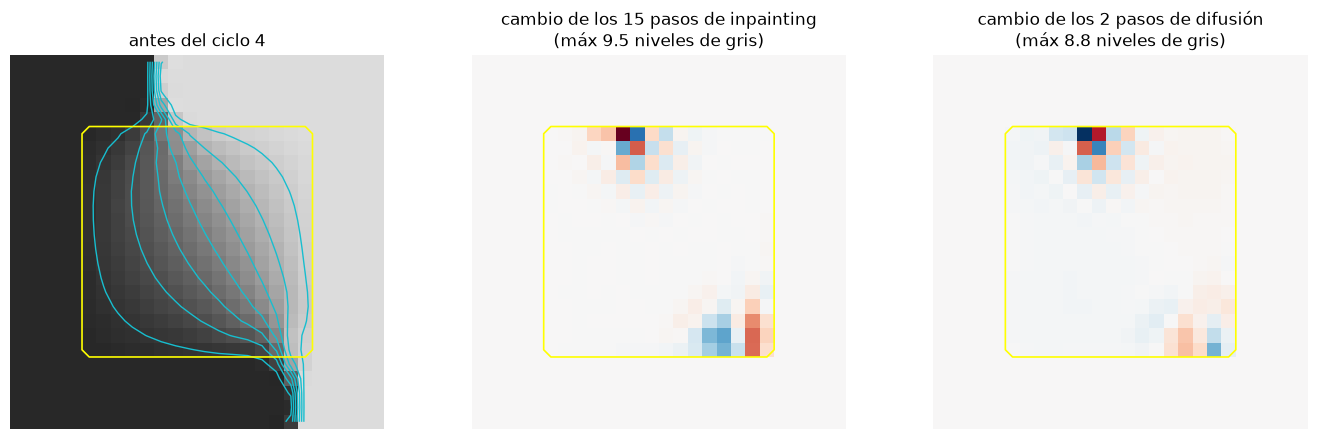

Correlación entre los dos cambios, dentro del hueco: -0.89


In [10]:
estados, estados_inpainting = historial(A0, h, 100)

ciclo = 4
antes = estados[ciclo - 1]
tras_transporte = estados_inpainting[ciclo]
despues = estados[ciclo]
cambio_transporte = (tras_transporte - antes)[w] * 255
cambio_difusion = (despues - tras_transporte)[w] * 255

fig, ejes = plt.subplots(1, 3, figsize=(14, 4.4))
ejes[0].imshow(antes[w], cmap="gray", vmin=0, vmax=1)
ejes[0].contour(antes[w], levels=niveles, colors="tab:cyan", linewidths=1)
ejes[0].set_title(f"antes del ciclo {ciclo}")
for eje, cambio, titulo in [(ejes[1], cambio_transporte, "cambio de los 15 pasos de inpainting"),
                            (ejes[2], cambio_difusion, "cambio de los 2 pasos de difusión")]:
    lim = np.abs(cambio).max()
    eje.imshow(cambio, cmap="RdBu_r", vmin=-lim, vmax=lim)
    eje.set_title(f"{titulo}\n(máx {lim:.1f} niveles de gris)")
for eje in ejes:
    marcar_hueco(eje, hv)
    eje.axis("off")
plt.tight_layout()
plt.show()

correlacion = np.corrcoef(cambio_transporte[hv], cambio_difusion[hv])[0, 1]
print(f"Correlación entre los dos cambios, dentro del hueco: {correlacion:+.2f}")

Cada fase hace una cosa distinta:

- **Inpainting (transporte):** lleva hacia dentro los valores a lo largo de las isófotas. Es lo que «dibuja» el borde.
- **Difusión anisotrópica:** suaviza las isófotas según su curvatura (ec. (3)). Corrige las irregularidades que ha dejado el transporte, que es lo que [1, sec. 3.3, p. 420] busca al intercalarla.

Si los dos cambios tienen **signo contrario** en una zona (correlación negativa), la difusión está deshaciendo parte de lo que ha hecho el transporte ahí.

### 2.3 Ciclo a ciclo: cómo se van moviendo las isófotas

Ahora seguimos el hueco a lo largo de 100 ciclos. Hay **tres filas**:

1. La imagen con sus **isófotas** (los mismos niveles en todas las columnas).
2. Lo que **ha cambiado** desde la columna anterior (rojo sube, azul baja, escala propia en cada panel).
3. El **módulo del gradiente** $\lvert\nabla I\rvert$ (claro = hay un borde). Todas con la misma escala.

El título de cada columna da el MSE del hueco respecto al original en ese ciclo.

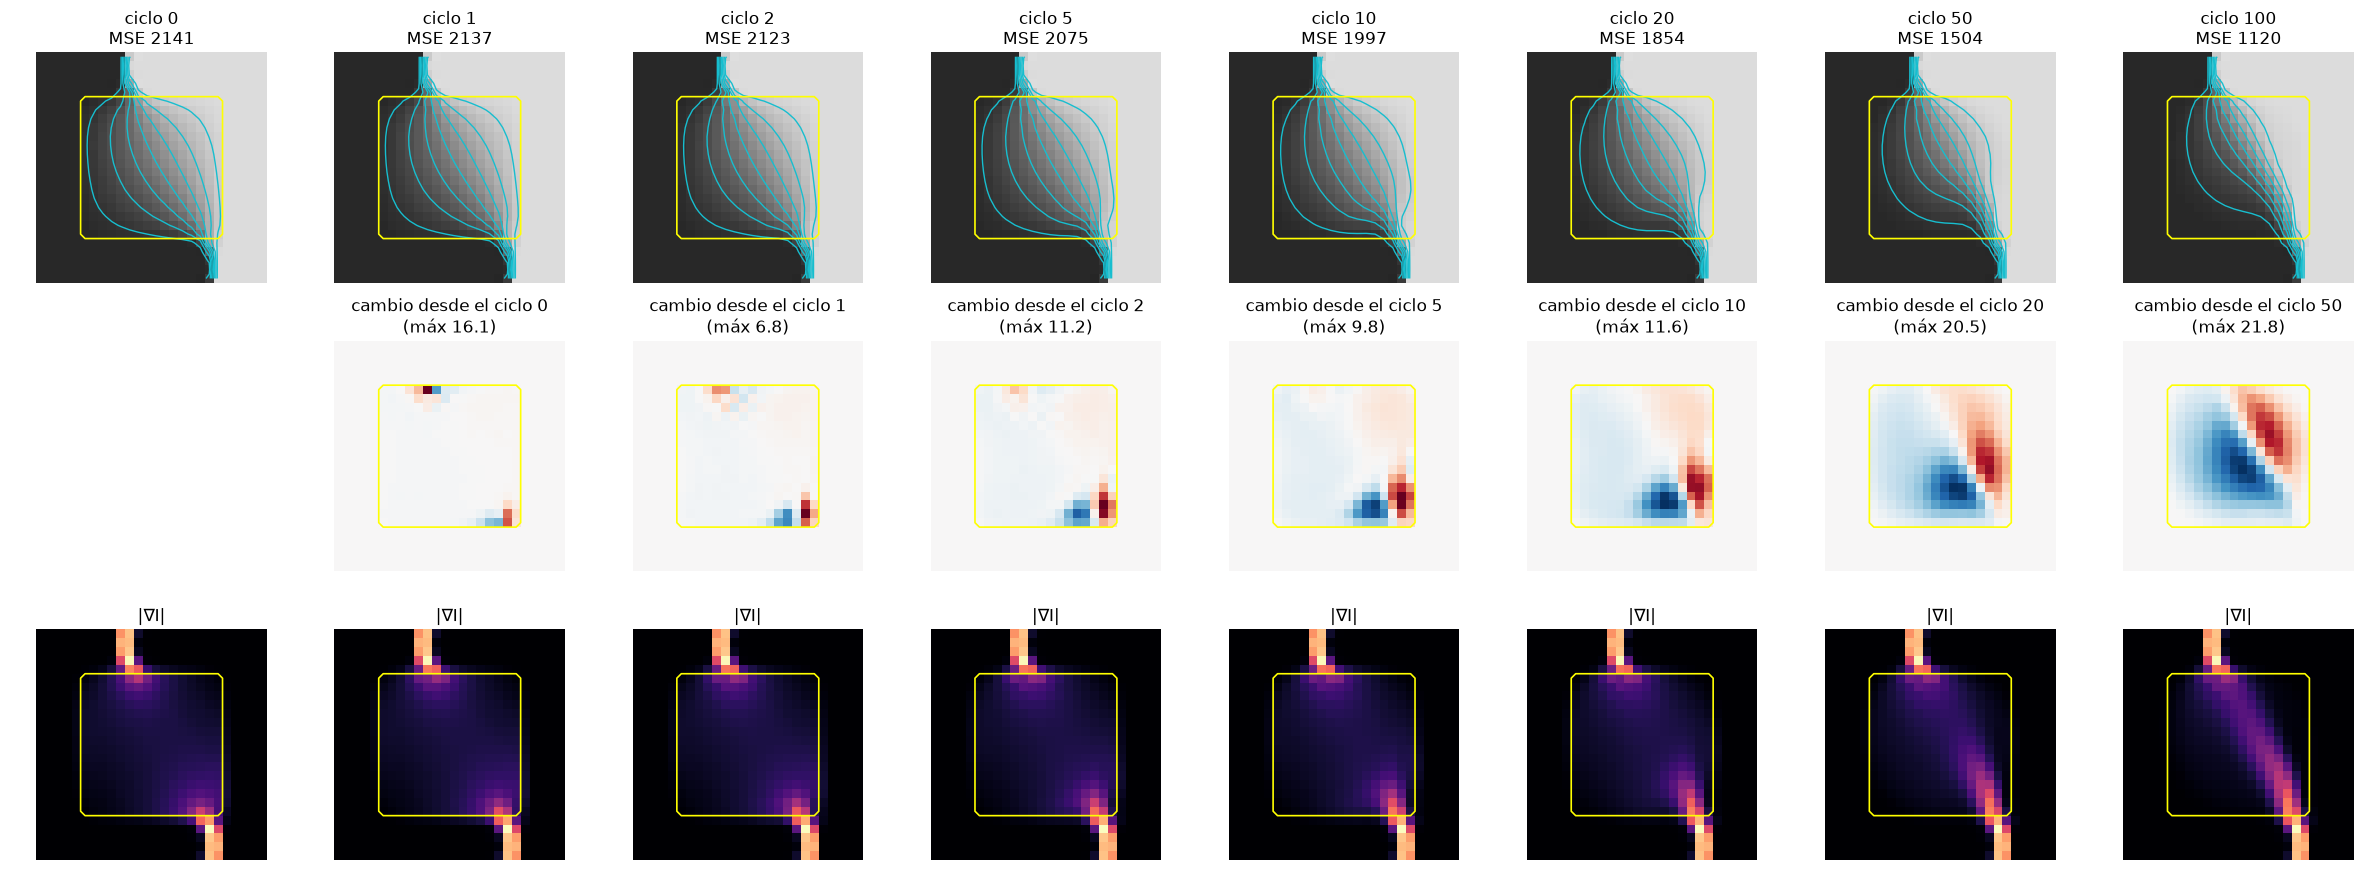

In [11]:
marcas = [0, 1, 2, 5, 10, 20, 50, 100]
mse_ciclo = error_por_ciclo(estados, h, original_zona)
escala_gradiente = np.hypot(*np.gradient(estados[0][w])).max()

fig, ejes = plt.subplots(3, len(marcas), figsize=(3 * len(marcas), 8.8))
for columna, n in enumerate(marcas):
    A_n = estados[n]
    ejes[0, columna].imshow(A_n[w], cmap="gray", vmin=0, vmax=1)
    ejes[0, columna].contour(A_n[w], levels=niveles, colors="tab:cyan", linewidths=1)
    ejes[0, columna].set_title(f"ciclo {n}\nMSE {mse_ciclo[n]:.0f}")

    gy, gx = np.gradient(A_n[w])
    ejes[2, columna].imshow(np.hypot(gx, gy), cmap="magma", vmin=0, vmax=escala_gradiente)
    ejes[2, columna].set_title(r"|∇I|")

    if n == 0:
        ejes[1, columna].axis("off")
    else:
        anterior = estados[marcas[columna - 1]]
        cambio = (A_n - anterior)[w] * 255
        lim = max(np.abs(cambio).max(), 1e-9)
        ejes[1, columna].imshow(cambio, cmap="RdBu_r", vmin=-lim, vmax=lim)
        ejes[1, columna].set_title(f"cambio desde el ciclo {marcas[columna - 1]}\n(máx {lim:.1f})")
    for fila in range(3):
        if not (fila == 1 and n == 0):
            marcar_hueco(ejes[fila, columna], hv)
        ejes[fila, columna].axis("off")
plt.tight_layout()
plt.show()

Lo que se ve:

- **Al principio las isófotas de dentro son curvas suaves** que unen unos puntos del borde con otros (es el resultado de la difusión simple). El cambio se concentra en los puntos donde el borde real toca el hueco.
- **A medida que pasan los ciclos, las isófotas se van enderezando** y se acercan unas a otras: el borde recto va tomando forma. En la fila de abajo se ve cómo el gradiente, que al principio es una mancha difusa, se concentra en una línea diagonal (el borde que continúa).
- **El cambio por ciclo es cada vez menor**: el algoritmo avanza rápido al principio y despacio después.

### 2.4 La curva de error: ¿cuántos ciclos hacen falta?

Cada ciclo es un paso de «iteración» del algoritmo. Seguimos 600 ciclos (el máximo por defecto de `bertalmio`) y dibujamos el error del hueco y el mayor cambio de un píxel en cada ciclo.

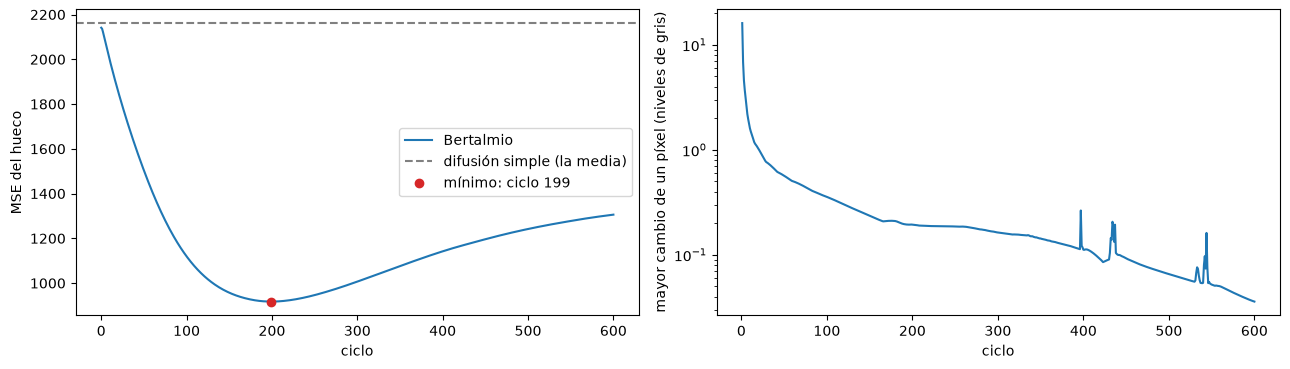

MSE de la media: 2162. Bertalmio: ciclo 0 = 2141, mínimo = 918 (ciclo 199), ciclo 600 = 1306.


In [12]:
estados_largo, _ = historial(A0, h, 600)
mse_largo = error_por_ciclo(estados_largo, h, original_zona)
cambio_largo = [np.abs(estados_largo[n + 1] - estados_largo[n])[h].max() * 255 for n in range(600)]
mse_media = k.mse(borde_i, d.difusion_simple(danada_i, hueco_i)[0], hueco_i)
mejor = int(np.argmin(mse_largo))

fig, ejes = plt.subplots(1, 2, figsize=(13, 3.8))
ejes[0].plot(range(601), mse_largo, label="Bertalmio")
ejes[0].axhline(mse_media, color="gray", linestyle="--", label="difusión simple (la media)")
ejes[0].plot([mejor], [mse_largo[mejor]], "o", color="tab:red", label=f"mínimo: ciclo {mejor}")
ejes[0].set_xlabel("ciclo")
ejes[0].set_ylabel("MSE del hueco")
ejes[0].legend()
ejes[1].semilogy(range(1, 601), cambio_largo)
ejes[1].set_xlabel("ciclo")
ejes[1].set_ylabel("mayor cambio de un píxel (niveles de gris)")
plt.tight_layout()
plt.show()

print(f"MSE de la media: {mse_media:.0f}. Bertalmio: ciclo 0 = {mse_largo[0]:.0f}, mínimo = {mse_largo[mejor]:.0f} (ciclo {mejor}), ciclo 600 = {mse_largo[600]:.0f}.")

Dos cosas importantes:

- **Es lento:** el cambio por ciclo baja en general (con algún pico pequeño en la curva, hacia los ciclos 400 a 540), pero ni con 600 ciclos llega a cero.
- **El error no baja siempre.** En este ejemplo llega a un mínimo y después **vuelve a subir** al seguir iterando. Una posible explicación es que el MSE castiga más un borde nítido que queda un poco fuera de su sitio que un borrón (lo mismo que vimos con el borde curvo, sección 6), pero no lo hemos comprobado. Lo que sí vemos es que el resultado final (sección 6) depende de **cuántos ciclos** se hagan, y es una decisión que tendremos que fijar en la experimentación.

### 2.5 El mismo seguimiento con la Fig. 4 del artículo

Hacemos lo mismo con el ejemplo del anillo de la sección 4: dos elipses oscuras sobre fondo gris y un hueco en forma de anillo. Aquí se ve mejor el efecto de **unir** los dos lados del hueco. En la fila de abajo se ve cada vez lo que ha cambiado.

Diferencia máxima con b.bertalmio: 0.0


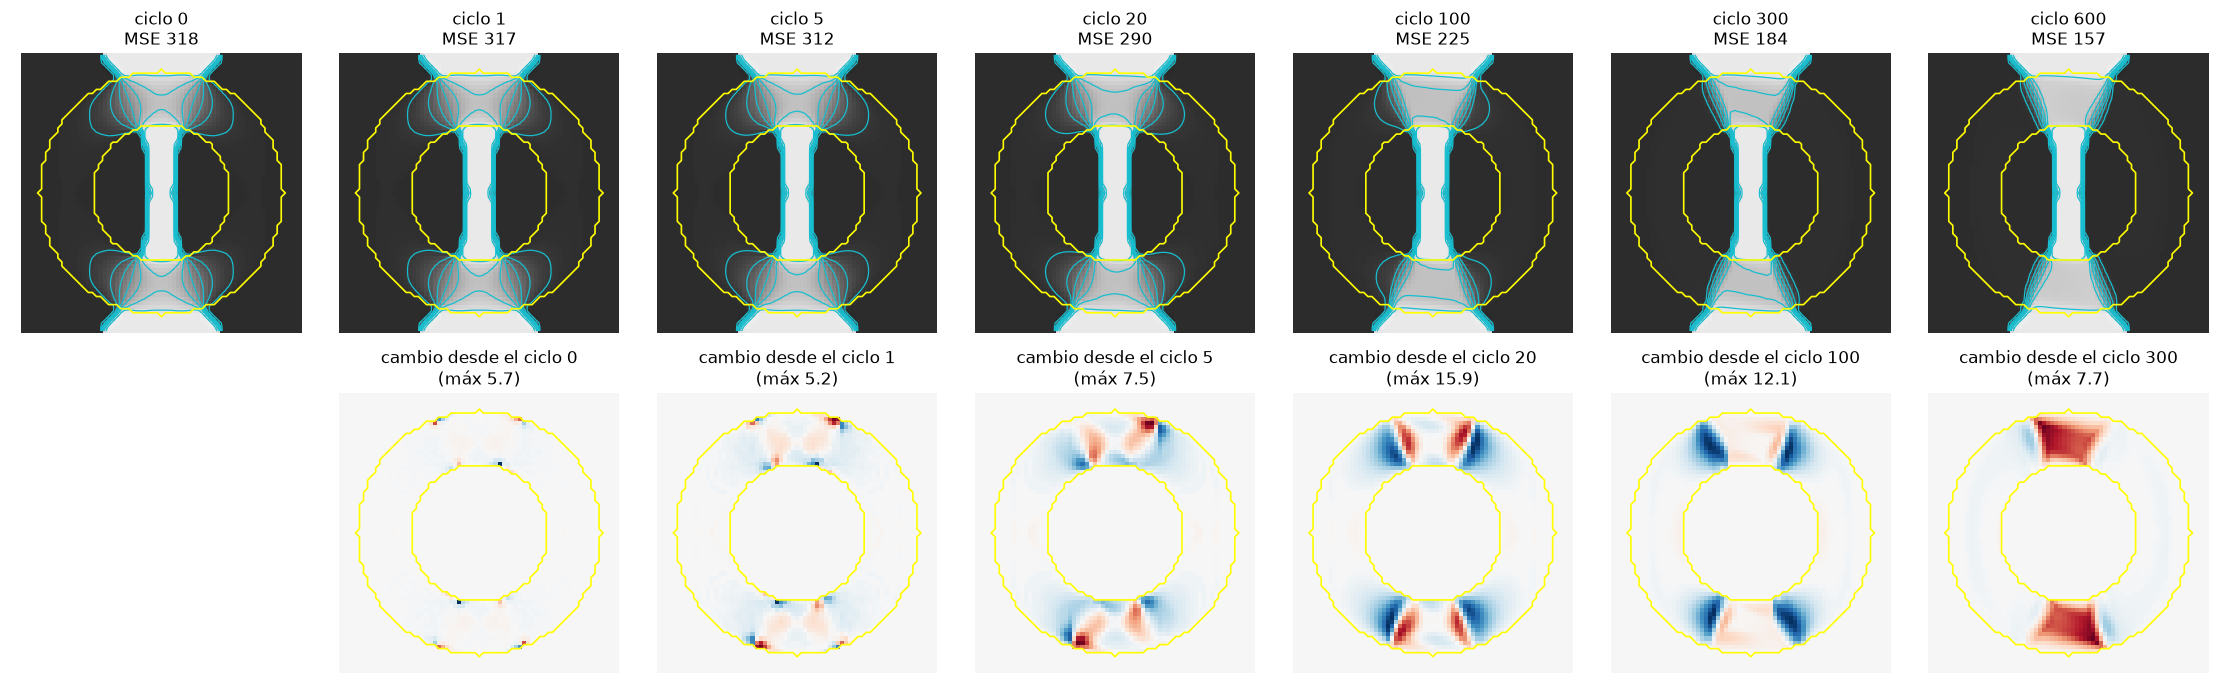

In [13]:
alto, ancho = 100, 140
filas, columnas = np.mgrid[0:alto, 0:ancho]
elipses_p = np.full((alto, ancho), 128, dtype=np.uint8)
for centro in (45, 95):
    elipses_p[((columnas - centro) / 22) ** 2 + ((filas - 50) / 38) ** 2 <= 1] = 25
distancia2 = (columnas - 70) ** 2 + (filas - 50) ** 2
anillo_p = (distancia2 <= 30 ** 2) & (distancia2 >= 17 ** 2)
danada_p = m.aplicar_mascara(elipses_p, anillo_p)

A0_p, h_p, zona_p = preparar(danada_p, anillo_p)
estados_p, _ = historial(A0_p, h_p, 600)

# Comprobación: nuestro bucle da lo mismo que b.bertalmio con los 600 ciclos.
con_bertalmio_p, _ = b.bertalmio(danada_p, anillo_p, ciclos=600, tolerancia=0)
con_nuestro_p = np.rint(estados_p[-1][3:-3, 3:-3] * 255)
diferencia_p = np.abs(con_nuestro_p[h_p[3:-3, 3:-3]] - con_bertalmio_p[zona_p][h_p[3:-3, 3:-3]]).max()
print("Diferencia máxima con b.bertalmio:", diferencia_p)
assert diferencia_p == 0

w_p = ventana(h_p, 4)
hv_p = h_p[w_p]
mse_p = error_por_ciclo(estados_p, h_p, elipses_p[zona_p] / 255)
niveles_p = np.linspace(0.12, 0.48, 7)
marcas_p = [0, 1, 5, 20, 100, 300, 600]

fig, ejes = plt.subplots(2, len(marcas_p), figsize=(3.2 * len(marcas_p), 6.8))
for columna, n in enumerate(marcas_p):
    A_n = estados_p[n]
    ejes[0, columna].imshow(A_n[w_p], cmap="gray", vmin=0, vmax=0.55)
    ejes[0, columna].contour(A_n[w_p], levels=niveles_p, colors="tab:cyan", linewidths=0.9)
    ejes[0, columna].set_title(f"ciclo {n}\nMSE {mse_p[n]:.0f}")
    if n == 0:
        ejes[1, columna].axis("off")
    else:
        anterior = estados_p[marcas_p[columna - 1]]
        cambio = (A_n - anterior)[w_p] * 255
        lim = np.abs(cambio).max()
        ejes[1, columna].imshow(cambio, cmap="RdBu_r", vmin=-lim, vmax=lim)
        ejes[1, columna].set_title(f"cambio desde el ciclo {marcas_p[columna - 1]}\n(máx {lim:.1f})")
        marcar_hueco(ejes[1, columna], hv_p)
    marcar_hueco(ejes[0, columna], hv_p)
    for fila in range(2):
        ejes[fila, columna].axis("off")
plt.tight_layout(h_pad=3)
plt.show()

Aquí se ve cómo va **entrando** la información desde los puntos donde los contornos de las elipses llegan al anillo. Al principio las isófotas de dentro del anillo son manchas redondeadas pegadas al borde; con los ciclos se estiran hacia el interior del anillo siguiendo los contornos de las elipses, y el error baja (318, 290, 225, 184 y 157 en los ciclos 0, 20, 100, 300 y 600). A diferencia del ejemplo anterior, aquí el error **sigue bajando hasta los 600 ciclos**, y la ejecución tarda unos segundos.

## 3. Por qué trabajamos con valores entre 0 y 1

El artículo da $\Delta t=0{,}1$ pero no dice en qué escala están los valores de la imagen. La actualización $I_t=\beta\lvert\nabla I\rvert$ es un transporte, y para que sea estable el producto $\Delta t\cdot\beta$ debe ser pequeño. Con valores de 0 a 255, $\beta$ sale unos cientos de veces mayor. Lo comprobamos repitiendo 60 pasos con `dt = 0.1` en las dos escalas sobre la misma imagen:

In [14]:
forma_s = (64, 64)
banda = m.mascara_aranazo(forma_s, (0, 32), (63, 32), 4)
base = np.where(banda, 0.2, 0.88)
hueco_s = m.mascara_cuadrada(forma_s, 20, (32, 32))

for nombre, escala in [("de 0 a 1  ", 1), ("de 0 a 255", 255)]:
    A = base * escala
    A[hueco_s] = A[~hueco_s].mean()
    with np.errstate(all="ignore"):
        for _ in range(60):
            A = b.paso_inpainting(A, hueco_s, 0.1)
    print(f"Valores {nombre}: máximo tras 60 pasos =", np.nanmax(np.abs(A)) if np.isfinite(A).all() else "se ha disparado (NaN)")

Valores de 0 a 1  : máximo tras 60 pasos = 0.88
Valores de 0 a 255: máximo tras 60 pasos = se ha disparado (NaN)


Con valores entre 0 y 1 se mantiene acotado y con valores de 0 a 255 **se dispara**. Es una elección nuestra, no del artículo. `bertalmio` divide las imágenes de 8 bits entre 255 antes de empezar.

## 4. Reproducción de la Fig. 4 del artículo

La Fig. 4 de [1, p. 421] es un ejemplo sintético: dos elipses oscuras sobre fondo gris y un hueco en forma de **anillo** (con un agujero en medio) que tapa parte de las dos. El artículo muestra que los contornos se recuperan, uniendo los puntos del borde interior y del exterior del anillo. Construimos una imagen parecida.

Media    : MSE del hueco    323   PSNR del hueco 23.04 dB
Bertalmio: MSE del hueco    158   PSNR del hueco 26.15 dB   (600 ciclos, 3.1 s)


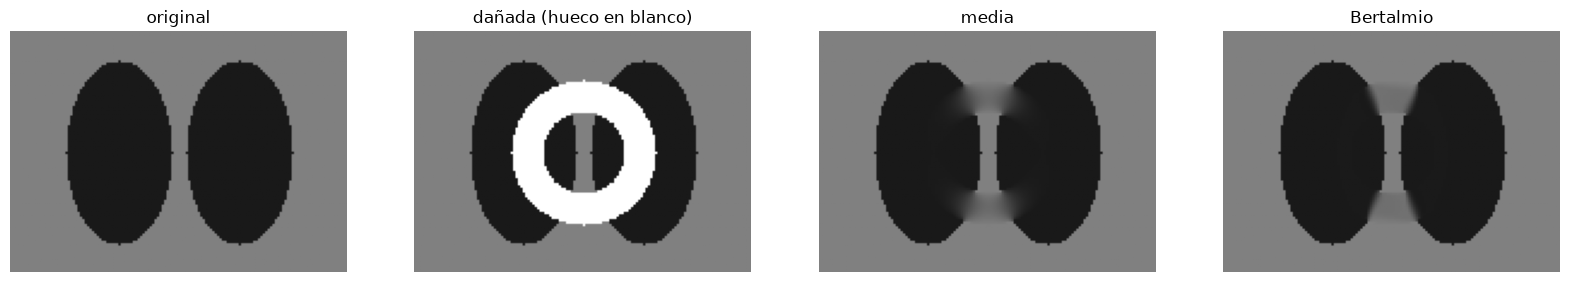

In [15]:
alto, ancho = 100, 140
filas, columnas = np.mgrid[0:alto, 0:ancho]
elipses = np.full((alto, ancho), 128, dtype=np.uint8)
for centro in (45, 95):
    elipses[((columnas - centro) / 22) ** 2 + ((filas - 50) / 38) ** 2 <= 1] = 25

distancia2 = (columnas - 70) ** 2 + (filas - 50) ** 2
anillo = (distancia2 <= 30 ** 2) & (distancia2 >= 17 ** 2)
danada_e = m.aplicar_mascara(elipses, anillo)

media_e, _ = d.difusion_simple(danada_e, anillo)
(bert_e, ciclos_e), tiempo_e, _ = k.cronometrar(b.bertalmio, danada_e, anillo, repeticiones=1)

print(f"Media    : MSE del hueco {k.mse(elipses, media_e, anillo):6.0f}   PSNR del hueco {k.psnr(elipses, media_e, anillo):5.2f} dB")
print(f"Bertalmio: MSE del hueco {k.mse(elipses, bert_e, anillo):6.0f}   PSNR del hueco {k.psnr(elipses, bert_e, anillo):5.2f} dB   ({ciclos_e} ciclos, {tiempo_e:.1f} s)")

plt.figure(figsize=(20, 4))
for numero, (titulo, im) in enumerate([("original", elipses), ("dañada (hueco en blanco)", danada_e), ("media", media_e), ("Bertalmio", bert_e)]):
    plt.subplot(1, 4, numero + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(titulo)
    plt.axis("off")
plt.show()

Bertalmio recupera los contornos de las elipses a través del anillo, con bordes nítidos, como en la Fig. 4 del artículo. La media los difumina. El error del hueco es aproximadamente la **mitad** con Bertalmio.

La misma prueba en color, con el modelo de color del artículo:

In [16]:
elipses_color = np.stack([elipses, (elipses * 0.9).astype(np.uint8), (elipses * 0.7).astype(np.uint8)], axis=-1)
danada_c = m.aplicar_mascara(elipses_color, anillo)
media_c, _ = d.difusion_simple(danada_c, anillo)
bert_c, _ = b.bertalmio(danada_c, anillo)
print(f"En color. Media: MSE {k.mse(elipses_color, media_c, anillo):.0f}   Bertalmio: MSE {k.mse(elipses_color, bert_c, anillo):.0f}")

En color. Media: MSE 248   Bertalmio: MSE 125


## 5. El valor de partida importa

El artículo dice que el resultado es robusto al valor inicial del hueco [1, sec. 4, p. 420], pero no dice cuál usa. Probamos tres:

- **difusión**: el resultado de la difusión simple (nuestra elección por defecto);
- **media**: un valor plano, la media de los píxeles conocidos;
- **ruido**: valores al azar, como en la implementación de referencia de Parisotto y Schönlieb.

inicio = difusion  MSE del hueco    158


inicio = media     MSE del hueco   1348


inicio = ruido     MSE del hueco   4654


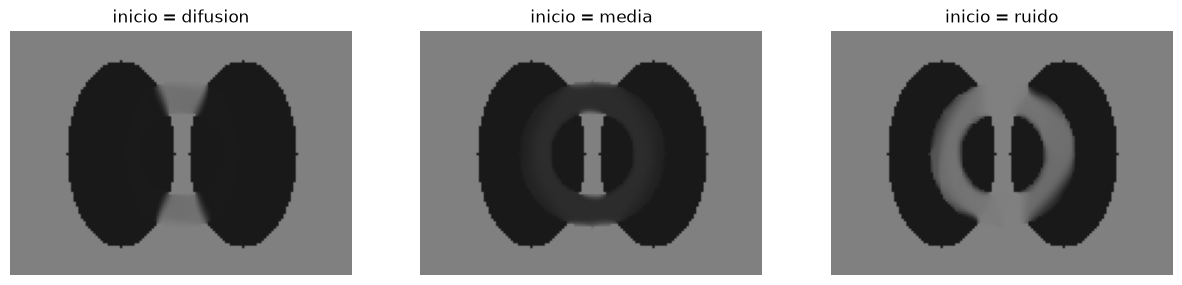

In [17]:
plt.figure(figsize=(15, 4))
for numero, inicio in enumerate(["difusion", "media", "ruido"]):
    r, _ = b.bertalmio(danada_e, anillo, inicio=inicio)
    print(f"inicio = {inicio:9s} MSE del hueco {k.mse(elipses, r, anillo):6.0f}")
    plt.subplot(1, 3, numero + 1)
    plt.imshow(r, cmap="gray", vmin=0, vmax=255)
    plt.title(f"inicio = {inicio}")
    plt.axis("off")
plt.show()

En nuestras pruebas **no es robusto**: solo partiendo de la difusión se recuperan los contornos. La explicación está en el propio artículo, que habla de un «problema de arranque» [1, sec. 3.2, p. 419]: para propagar la información hace falta conocer la dirección de las isófotas dentro del hueco, y eso es tanto como conocer la imagen.

- Con un hueco **plano**, las únicas isófotas son las del borde del hueco, paralelas a él. El transporte solo mueve ese borde y la información no entra.
- Con **ruido**, hay isófotas en todas direcciones al azar y el transporte no sabe por dónde llevar la información.
- Con la **difusión**, las isófotas ya cruzan el hueco uniendo puntos del borde, de forma suave. El transporte las sigue y las endereza para que continúen las de fuera.

Esto encaja con lo que hace el artículo en los huecos grandes: usa multirresolución, es decir, resuelve primero a baja resolución y usa ese resultado como punto de partida [1, nota 10, p. 420].

## 6. Bordes rectos y curvos

Imágenes sintéticas con un borde inclinado y un borde curvo, y un hueco de 16×16 encima. A propósito no son simétricas, para que el sentido de giro de $N$ no quede oculto.

caso              MSE del hueco: media   Bertalmio


borde inclinado                   2162        1304


borde curvo                       3468        3707


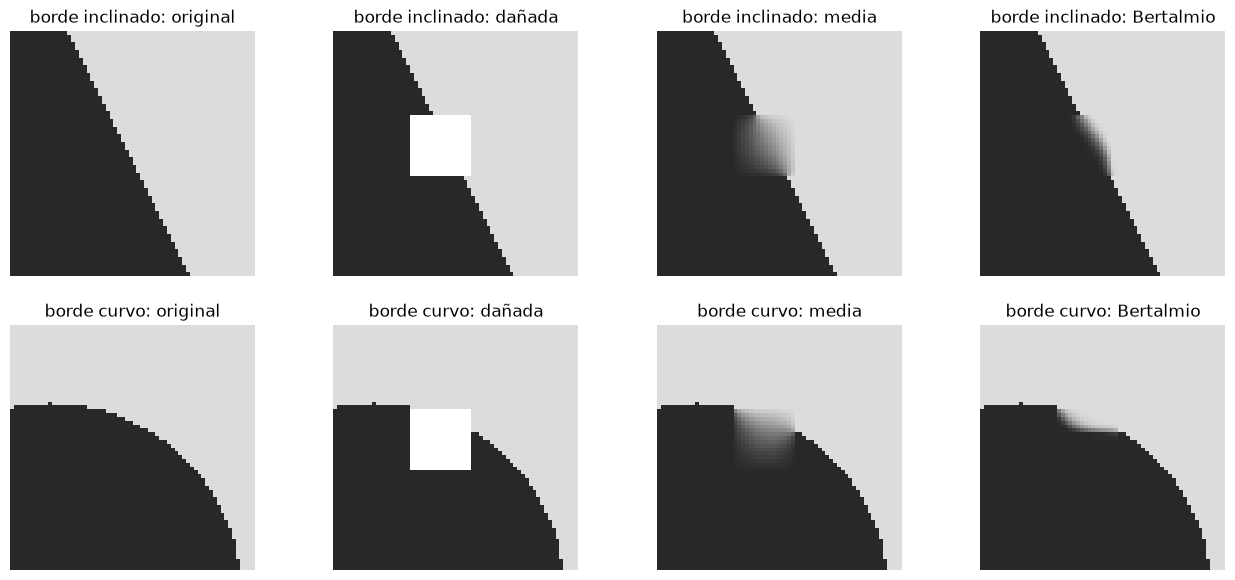

In [18]:
N = 64
filas_s, columnas_s = np.mgrid[0:N, 0:N]
casos = {
    "borde inclinado": np.where(2 * columnas_s - filas_s >= 30, 220, 40).astype(np.uint8),
    "borde curvo": np.where((filas_s - 70) ** 2 + (columnas_s - 10) ** 2 <= 50 ** 2, 40, 220).astype(np.uint8),
}
hueco_s = m.mascara_cuadrada((N, N), 16, (30, 28))

plt.figure(figsize=(16, 7))
print("caso              MSE del hueco: media   Bertalmio")
for fila, (nombre, sintetica) in enumerate(casos.items()):
    danada_s = m.aplicar_mascara(sintetica, hueco_s)
    media_s, _ = d.difusion_simple(danada_s, hueco_s)
    bert_s, _ = b.bertalmio(danada_s, hueco_s)
    print(f"{nombre:16s}   {k.mse(sintetica, media_s, hueco_s):19.0f}   {k.mse(sintetica, bert_s, hueco_s):9.0f}")
    for columna, (titulo, im) in enumerate([("original", sintetica), ("dañada", danada_s), ("media", media_s), ("Bertalmio", bert_s)]):
        plt.subplot(2, 4, fila * 4 + columna + 1)
        plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(f"{nombre}: {titulo}")
        plt.axis("off")
plt.show()

- **Borde inclinado:** Bertalmio continúa el borde nítido a través del hueco, y el error baja de 2162 a 1304.
- **Borde curvo:** el borde también sale nítido, pero más recto que el original, y el error queda algo por encima del de la media (3707 frente a 3468). Cuando el borde no cae exactamente en su sitio, el MSE castiga más un borde nítido mal colocado que un borrón. A la vista, el resultado de Bertalmio se parece más a una imagen real.

## 7. Limitaciones: líneas finas y texturas

### Una línea fina que cruza el hueco

Línea fina. Media: MSE 6055   Bertalmio: MSE 8833


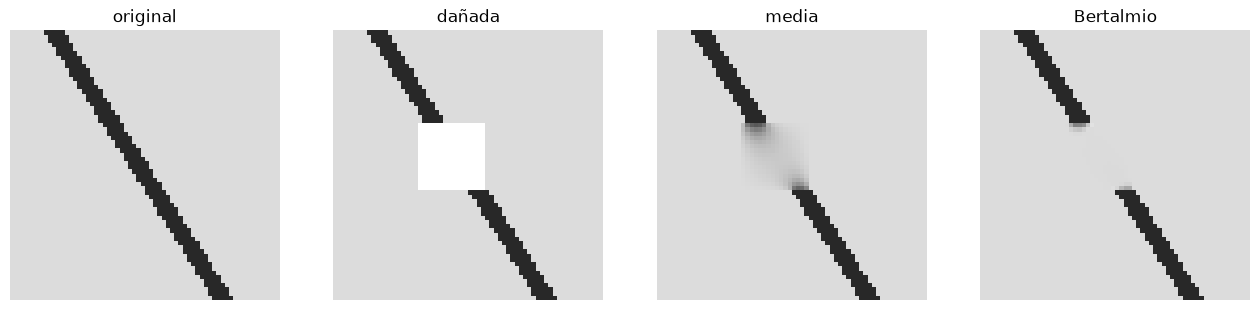

In [19]:
linea_mask = m.mascara_aranazo((N, N), (0, 10), (63, 50), 4)
linea = np.full((N, N), 220, dtype=np.uint8)
linea[linea_mask] = 40
danada_l = m.aplicar_mascara(linea, hueco_s)
media_l, _ = d.difusion_simple(danada_l, hueco_s)
bert_l, _ = b.bertalmio(danada_l, hueco_s)
print(f"Línea fina. Media: MSE {k.mse(linea, media_l, hueco_s):.0f}   Bertalmio: MSE {k.mse(linea, bert_l, hueco_s):.0f}")

plt.figure(figsize=(16, 4))
for numero, (titulo, im) in enumerate([("original", linea), ("dañada", danada_l), ("media", media_l), ("Bertalmio", bert_l)]):
    plt.subplot(1, 4, numero + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(titulo)
    plt.axis("off")
plt.show()

Una línea de 4 píxeles que cruza un hueco de 16 **no se reconecta**. Una línea fina son dos bordes muy juntos, y el hueco es cuatro veces más ancho que la línea. El artículo no enseña ningún ejemplo así: sus huecos con líneas son estrechos (grietas, texto, cables).

### Un cable fino sobre una foto real

Un caso parecido a los de las Figs. 5 a 8 del artículo: un hueco fino (un «cable» de 4 píxeles) que cruza zonas de rocas y de cielo.

Media    : MSE del hueco   548   tiempo   0.05 s
Bertalmio: MSE del hueco   665   tiempo  26.72 s


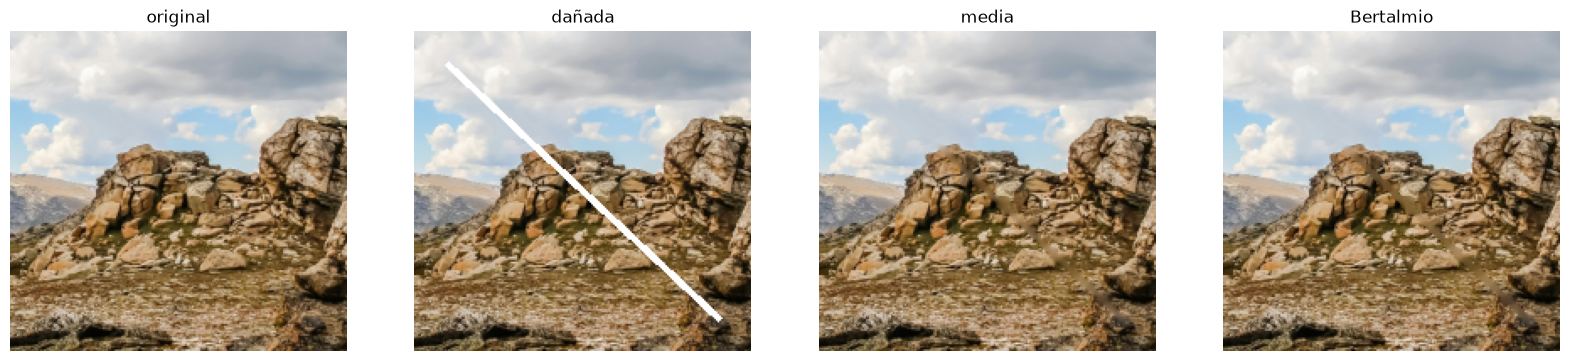

In [20]:
imagen = cv.imread("../images/originales/photo-1431315906474-0e7a186c0304.jpg")
imagen = cv.cvtColor(imagen, cv.COLOR_BGR2RGB)
escala = 512 / max(imagen.shape[:2])
imagen = cv.resize(imagen, (round(imagen.shape[1] * escala), round(imagen.shape[0] * escala)), interpolation=cv.INTER_AREA)

cable = m.mascara_aranazo(imagen.shape[:2], (130, 240), (280, 400), 4)
danada_f = m.aplicar_mascara(imagen, cable)
(media_f, _), tiempo_media, _ = k.cronometrar(d.difusion_simple, danada_f, cable, repeticiones=1)
(bert_f, _), tiempo_bert, _ = k.cronometrar(b.bertalmio, danada_f, cable, repeticiones=1)

print(f"Media    : MSE del hueco {k.mse(imagen, media_f, cable):5.0f}   tiempo {tiempo_media:6.2f} s")
print(f"Bertalmio: MSE del hueco {k.mse(imagen, bert_f, cable):5.0f}   tiempo {tiempo_bert:6.2f} s")

ventana = (slice(110, 300), slice(220, 420))
plt.figure(figsize=(20, 5))
for numero, (titulo, im) in enumerate([("original", imagen), ("dañada", danada_f), ("media", media_f), ("Bertalmio", bert_f)]):
    plt.subplot(1, 4, numero + 1)
    plt.imshow(im[ventana])
    plt.title(titulo)
    plt.axis("off")
plt.show()

Los dos métodos **quitan el cable** y a la vista casi no se distingue por dónde pasaba, como en las fotos del artículo. En error, Bertalmio queda algo por encima de la media (665 frente a 548) y tarda mucho más (unos 27 s frente a 0,06 s). En zonas con textura no aporta una mejora clara, que es la limitación que reconoce el propio artículo [1, sec. 5, p. 421; Fig. 9, p. 424].

## Resumen

- `src/bertalmio.py` implementa las ecuaciones (1) a (10) de Bertalmio et al., con la ecuación y la página citadas en cada paso, y coincide con una implementación pública del método.
- **Se ve el progreso** (sección 2): las isófotas de dentro del hueco parten de curvas suaves y se van enderezando hasta continuar el borde; el cambio entra por los puntos donde el borde real toca el hueco. El error **no baja siempre**: en el borde inclinado llega a un mínimo y vuelve a subir.
- **Reproduce la Fig. 4 del artículo**: los contornos se recuperan a través del hueco en forma de anillo, con la mitad de error que la difusión simple, también en color.
- **El valor de partida es decisivo**: solo partiendo de la difusión simple funciona. Lo explica el «problema de arranque» del propio artículo.
- Continúa nítidos los **bordes** que cruzan el hueco: con uno inclinado baja mucho el error; con uno curvo lo deja nítido pero algo más recto. No reconecta una **línea fina** en un hueco ancho, y en una **foto con textura** queda parecido a la media (algo peor en error).
- Es mucho más lento que la media (segundos frente a centésimas).
- Pendiente para la siguiente fase: probarlo con muchas imágenes y máscaras y compararlo con el método de ejemplares.